# K Means Clustering(Unsupervised)


Dataset loaded successfully!
Dataset dimensions: (21025, 202)
Number of spectral bands: 200
Number of pixels: 21025

PCA Results
Reduced dimensions: (21025, 30)
Explained variance: 98.44 %

K-Means clustering completed!

Cluster Distribution:
Cluster 1: 1595 pixels
Cluster 2: 1581 pixels
Cluster 3: 2024 pixels
Cluster 4: 350 pixels
Cluster 5: 758 pixels
Cluster 6: 2738 pixels
Cluster 7: 152 pixels
Cluster 8: 938 pixels
Cluster 9: 1220 pixels
Cluster 10: 774 pixels
Cluster 11: 1249 pixels
Cluster 12: 540 pixels
Cluster 13: 2308 pixels
Cluster 14: 2203 pixels
Cluster 15: 1386 pixels
Cluster 16: 1209 pixels


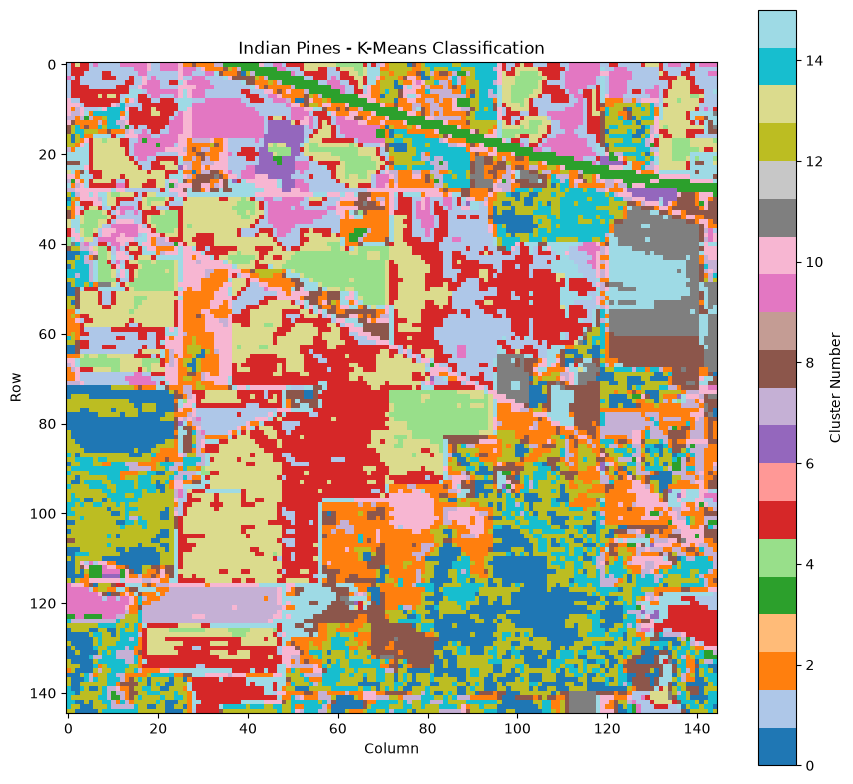

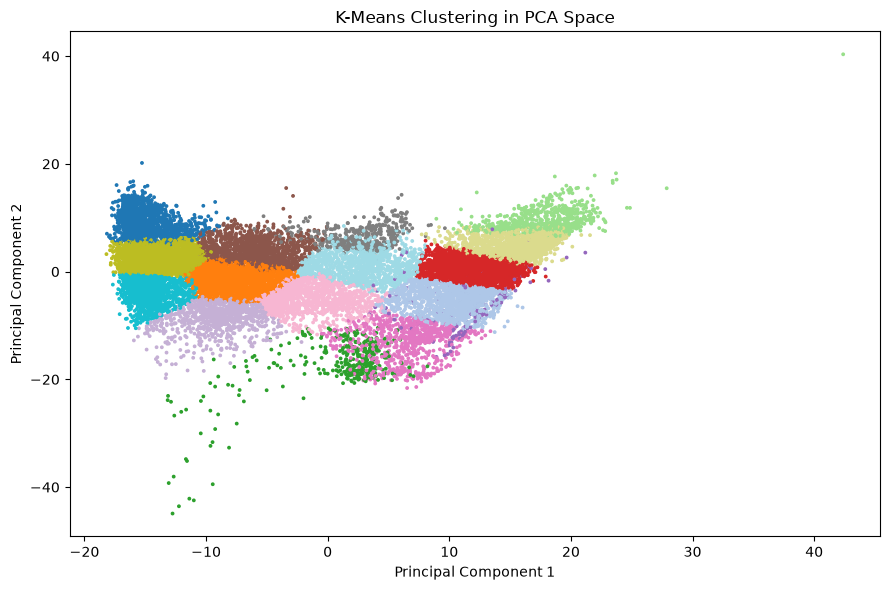

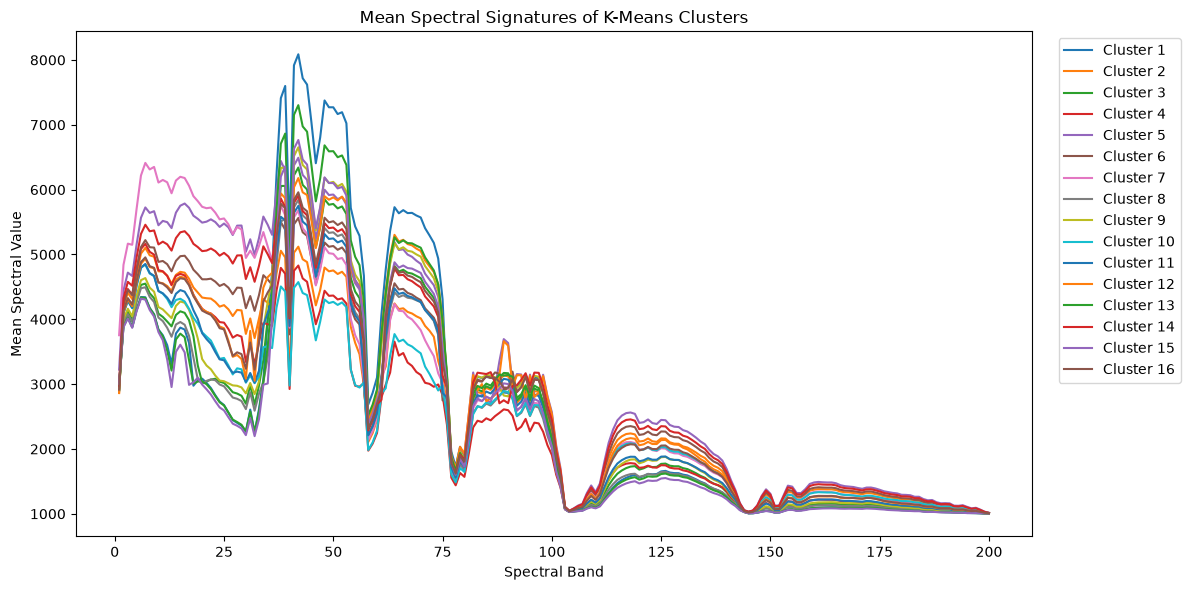


Results saved successfully!
CSV: indian_pines_kmeans_results.csv
Map: indian_pines_classification_map.npy


In [3]:

# K-MEANS CLUSTERING FOR INDIAN PINES HYPERSPECTRAL DATA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# 1. Load the dataset
data = pd.read_csv("indian_pines (1).csv")

print("Dataset loaded successfully!")
print("Dataset dimensions:", data.shape)

# 2. Extract spectral bands
band_columns = [c for c in data.columns if c.startswith("band_")]
band_columns = sorted(band_columns, key=lambda c: int(c.split("_")[1]))

X = data[band_columns].values

print("Number of spectral bands:", len(band_columns))
print("Number of pixels:", X.shape[0])

# 3. Handle missing values
X = np.nan_to_num(X, nan=0.0)

# 4. Standardize the spectral data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Apply PCA for dimensionality reduction
pca = PCA(n_components=30)
X_pca = pca.fit_transform(X_scaled)

print("\nPCA Results")
print("Reduced dimensions:", X_pca.shape)
print("Explained variance:",
      round(np.sum(pca.explained_variance_ratio_) * 100, 2), "%")

# 6. Apply K-Means clustering
kmeans = KMeans(
    n_clusters=16,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_pca)

print("\nK-Means clustering completed!")

# 7. Display cluster distribution
unique, counts = np.unique(clusters, return_counts=True)

print("\nCluster Distribution:")
for cluster, count in zip(unique, counts):
    print(f"Cluster {cluster + 1}: {count} pixels")

# 8. Reconstruct the spatial classification map
rows = data["row"].astype(int).to_numpy()
cols = data["col"].astype(int).to_numpy()

# Automatically handle zero-based or one-based coordinates
if rows.min() == 1 and cols.min() == 1:
    rows = rows - 1
    cols = cols - 1

height = rows.max() + 1
width = cols.max() + 1

classification_map = np.full((height, width), -1)

classification_map[rows, cols] = clusters

# 9. Visualize the classification map
plt.figure(figsize=(9, 8))
plt.imshow(classification_map, cmap="tab20")
plt.colorbar(label="Cluster Number")
plt.title("Indian Pines - K-Means Classification")
plt.xlabel("Column")
plt.ylabel("Row")
plt.tight_layout()
plt.show()

# 10. Visualize PCA clustering
plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="tab20",
    s=3
)
plt.title("K-Means Clustering in PCA Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

# 11. Plot mean spectral signatures of clusters
plt.figure(figsize=(12, 6))

for cluster in unique:
    mean_spectrum = X[clusters == cluster].mean(axis=0)
    plt.plot(
        range(1, len(band_columns) + 1),
        mean_spectrum,
        label=f"Cluster {cluster + 1}"
    )

plt.xlabel("Spectral Band")
plt.ylabel("Mean Spectral Value")
plt.title("Mean Spectral Signatures of K-Means Clusters")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 12. Save classification results
data["Cluster"] = clusters + 1

data.to_csv("indian_pines_kmeans_results.csv", index=False)

np.save("indian_pines_classification_map.npy",
        classification_map)

print("\nResults saved successfully!")
print("CSV: indian_pines_kmeans_results.csv")
print("Map: indian_pines_classification_map.npy")


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, cohen_kappa_score, classification_report

gt  = pd.read_csv("indian_pines_ground_truth.csv")   # row, col, label, class_name
img = pd.read_csv("indian_pines (1).csv")                # row, col, band_1 ... band_200

# match every pixel's spectrum to its label using (row, col)
df = img.merge(gt, on=["row", "col"], how="inner")
band_cols = [c for c in df.columns if c.startswith("band_")]
print("pixels:", len(df), "| bands:", len(band_cols))

# cube (145, 145, 200), only needed for the classification maps
H, W = df.row.max() + 1, df.col.max() + 1
cube = np.zeros((H, W, len(band_cols)), dtype="float32")
cube[df.row.values, df.col.values, :] = df[band_cols].values

X_all = df[band_cols].values.astype("float32")
y_all = df["label"].values

# drop class 0 (Unlabelled)
m = y_all > 0
X, y = X_all[m], y_all[m]
class_names = (df[df.label > 0].drop_duplicates("label")
                 .sort_values("label")["class_name"].tolist())

# stratified split: 30% train / 70% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.30, stratify=y, random_state=42)

# scaler (used by ANN and SVM; Random Forest does not need it)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print("train:", X_train.shape, "test:", X_test.shape)

def evaluate(model, Xte, title):
    pred = model.predict(Xte)
    print(f"{title}\nOverall accuracy: {accuracy_score(y_test, pred):.4f} | "
          f"Kappa: {cohen_kappa_score(y_test, pred):.4f}\n")
    print(classification_report(y_test, pred, target_names=class_names, zero_division=0))
    return pred

def show_map(model, use_scaler=False, title="Classification map"):
    """Predict every pixel and plot it next to the ground truth."""
    Xf = cube.reshape(-1, cube.shape[2])
    if use_scaler: Xf = scaler.transform(Xf)
    pred_map = model.predict(Xf).reshape(cube.shape[:2])
    gt_map = np.zeros(cube.shape[:2], int); gt_map[df.row, df.col] = df.label
    fig, ax = plt.subplots(1, 2, figsize=(11, 5))
    ax[0].imshow(gt_map, cmap="nipy_spectral"); ax[0].set_title("Ground truth")
    ax[1].imshow(pred_map, cmap="nipy_spectral"); ax[1].set_title(title)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

pixels: 21025 | bands: 200
train: (3074, 200) test: (7175, 200)


In [3]:

import pandas as pd
import numpy as np

from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Load datasets
kmeans = pd.read_csv("indian_pines_kmeans_results.csv")
gt = pd.read_csv("indian_pines_ground_truth.csv")

# Match pixels using coordinates whenever available
if all(c in kmeans.columns for c in ["row", "col"]) and \
   all(c in gt.columns for c in ["row", "col"]):

    data = pd.merge(
        kmeans[["row", "col", "Cluster"]],
        gt,
        on=["row", "col"],
        how="inner"
    )

    label_col = next(
        (c for c in ["class", "label", "ground_truth"]
         if c in data.columns),
        data.columns[-1]
    )

    actual = data[label_col].to_numpy()
    predicted = data["Cluster"].to_numpy()

else:
    # Use matching row order only if coordinates are unavailable
    actual = gt.iloc[:, -1].to_numpy()
    predicted = kmeans["Cluster"].to_numpy()

    if len(actual) != len(predicted):
        raise ValueError("CSV files have different pixel counts!")

# Remove unlabelled pixels
valid = actual != 0
actual = actual[valid]
predicted = predicted[valid]

# Create confusion matrix
classes = np.unique(actual)
clusters = np.unique(predicted)

cm = confusion_matrix(actual, predicted, labels=classes)

# Match clusters to classes using Hungarian algorithm
# Build a matrix with one column per cluster
match_matrix = np.zeros((len(classes), len(clusters)), dtype=int)

for i, cls in enumerate(classes):
    for j, cluster in enumerate(clusters):
        match_matrix[i, j] = np.sum(
            (actual == cls) & (predicted == cluster)
        )

row_ind, col_ind = linear_sum_assignment(-match_matrix)

mapping = {
    clusters[j]: classes[i]
    for i, j in zip(row_ind, col_ind)
}

matched = np.array([
    mapping.get(cluster, -1) for cluster in predicted
])

# Calculate metrics
accuracy = accuracy_score(actual, matched) * 100

precision = precision_score(
    actual, matched, average="weighted", zero_division=0
) * 100

recall = recall_score(
    actual, matched, average="weighted", zero_division=0
) * 100

f1 = f1_score(
    actual, matched, average="weighted", zero_division=0
) * 100

# Display results
print("\n========== K-MEANS RESULTS ==========")
print(f"Accuracy  : {accuracy:.2f}%")
print(f"Precision : {precision:.2f}%")
print(f"Recall    : {recall:.2f}%")
print(f"F1 Score  : {f1:.2f}%")



========== K-MEANS RESULTS ==========
Accuracy  : 36.85%
Precision : 46.69%
Recall    : 36.85%
F1 Score  : 39.61%


# Random Forest(Supervised)

RANDOM FOREST
Overall accuracy: 0.8162 | Kappa: 0.7885

                              precision    recall  f1-score   support

                     Alfalfa       0.88      0.47      0.61        32
                 Corn-notill       0.80      0.73      0.77      1000
                Corn-mintill       0.85      0.64      0.73       581
                        Corn       0.66      0.40      0.50       166
               Grass-pasture       0.93      0.89      0.91       338
                 Grass-trees       0.87      0.93      0.90       511
         Grass-pasture-mowed       0.83      0.50      0.62        20
               Hay-windrowed       0.90      0.98      0.94       335
                        Oats       1.00      0.29      0.44        14
              Soybean-notill       0.79      0.81      0.80       680
             Soybean-mintill       0.76      0.90      0.83      1719
               Soybean-clean       0.71      0.62      0.66       415
                       Wheat     

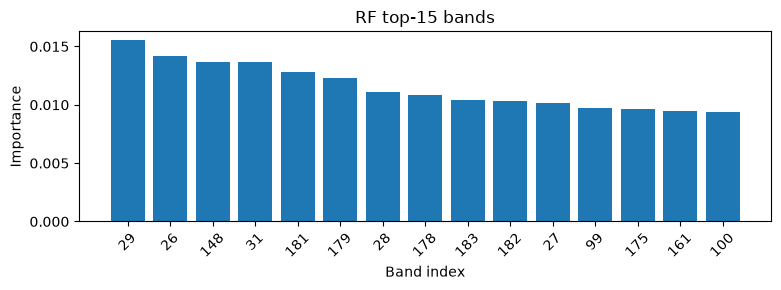

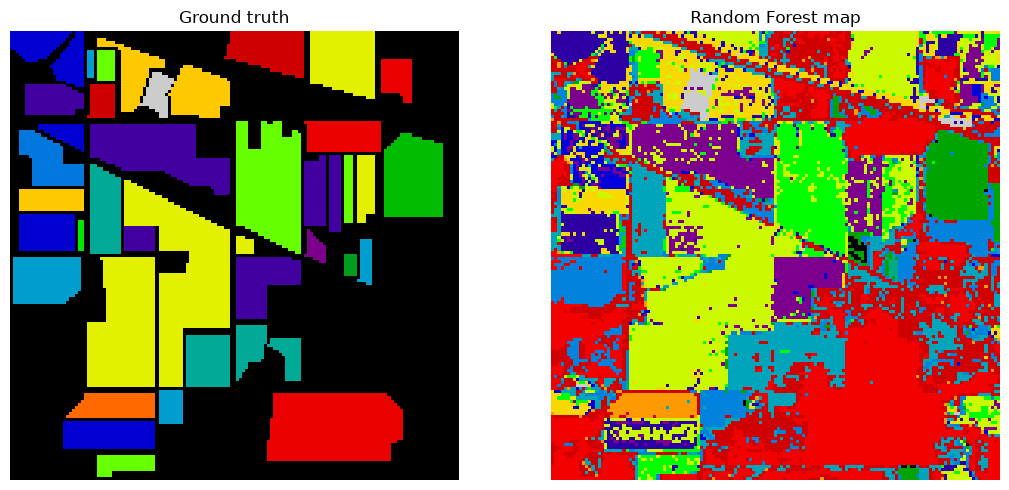

In [3]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, max_features="sqrt",
                            n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)                       # no scaling needed for trees

pred_rf = evaluate(rf, X_test, "RANDOM FOREST")

# top 15 most important spectral bands
imp = rf.feature_importances_
top = np.argsort(imp)[::-1][:15]
plt.figure(figsize=(8, 3)); plt.bar(range(15), imp[top])
plt.xticks(range(15), top, rotation=45); plt.xlabel("Band index"); plt.ylabel("Importance")
plt.title("RF top-15 bands"); plt.tight_layout(); plt.show()

show_map(rf, use_scaler=False, title="Random Forest map")

# ANN

ANN (MLP)
Overall accuracy: 0.8694 | Kappa: 0.8506

                              precision    recall  f1-score   support

                     Alfalfa       0.88      0.44      0.58        32
                 Corn-notill       0.91      0.80      0.85      1000
                Corn-mintill       0.85      0.81      0.83       581
                        Corn       0.75      0.78      0.76       166
               Grass-pasture       0.92      0.90      0.91       338
                 Grass-trees       0.97      0.96      0.97       511
         Grass-pasture-mowed       0.86      0.90      0.88        20
               Hay-windrowed       0.94      0.99      0.97       335
                        Oats       0.80      0.86      0.83        14
              Soybean-notill       0.86      0.81      0.83       680
             Soybean-mintill       0.81      0.91      0.86      1719
               Soybean-clean       0.86      0.81      0.83       415
                       Wheat       0.

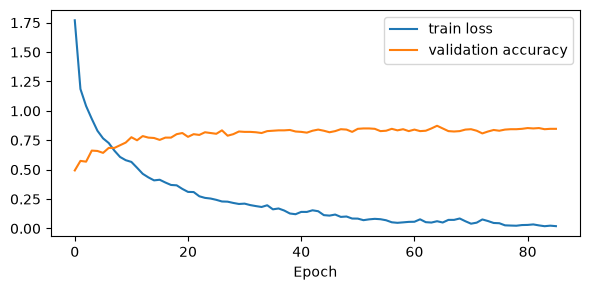

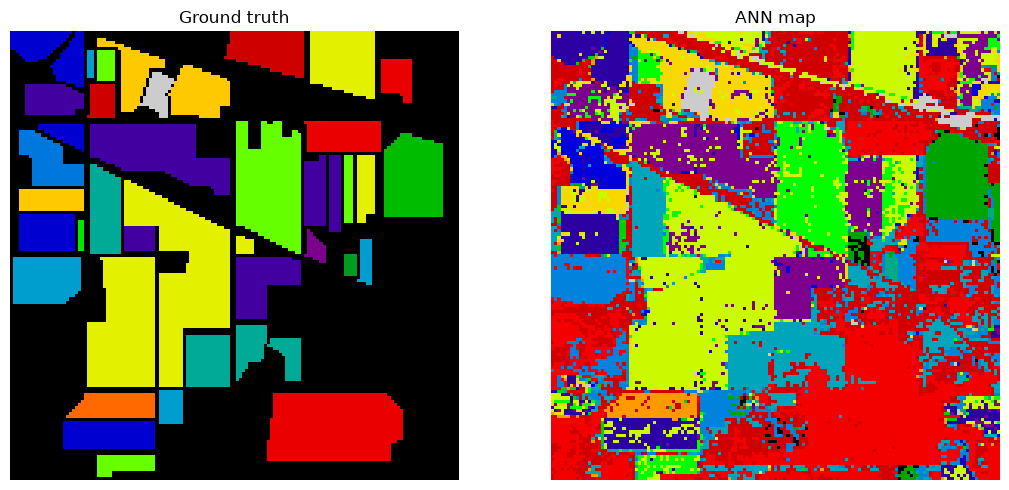

In [4]:
from sklearn.neural_network import MLPClassifier

ann = MLPClassifier(hidden_layer_sizes=(256, 128, 64), activation="relu",
                    solver="adam", alpha=1e-4, batch_size=128,
                    learning_rate_init=1e-3, max_iter=300,
                    early_stopping=True, validation_fraction=0.1,
                    n_iter_no_change=20, random_state=42)
ann.fit(X_train_s, y_train)                    # ANN needs scaled inputs

pred_ann = evaluate(ann, X_test_s, "ANN (MLP)")

plt.figure(figsize=(6, 3)); plt.plot(ann.loss_curve_, label="train loss")
plt.plot(ann.validation_scores_, label="validation accuracy")
plt.xlabel("Epoch"); plt.legend(); plt.tight_layout(); plt.show()

show_map(ann, use_scaler=True, title="ANN map")

# Support Vector Machine

Fitting 3 folds for each of 9 candidates, totalling 27 fits
Best params: {'C': 100, 'gamma': 0.005} | CV acc: 0.8549
SVM (RBF)
Overall accuracy: 0.8734 | Kappa: 0.8561

                              precision    recall  f1-score   support

                     Alfalfa       0.91      0.66      0.76        32
                 Corn-notill       0.82      0.87      0.84      1000
                Corn-mintill       0.82      0.80      0.81       581
                        Corn       0.75      0.69      0.72       166
               Grass-pasture       0.94      0.94      0.94       338
                 Grass-trees       0.95      0.97      0.96       511
         Grass-pasture-mowed       0.90      0.90      0.90        20
               Hay-windrowed       0.97      0.99      0.98       335
                        Oats       0.92      0.79      0.85        14
              Soybean-notill       0.79      0.89      0.84       680
             Soybean-mintill       0.89      0.82      0.86 

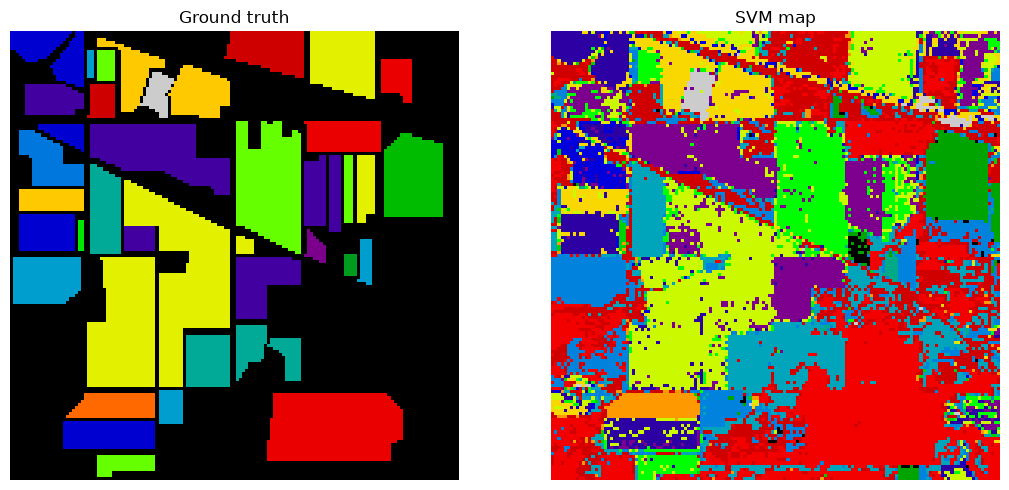

In [5]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(SVC(kernel="rbf", class_weight="balanced"),
                    param_grid={"C": [10, 100, 1000], "gamma": [0.001, 0.005, 0.01]},
                    cv=3, n_jobs=-1, verbose=1)
grid.fit(X_train_s, y_train)                   # SVM needs scaled inputs
print("Best params:", grid.best_params_, "| CV acc:", round(grid.best_score_, 4))
svm = grid.best_estimator_

pred_svm = evaluate(svm, X_test_s, "SVM (RBF)")

show_map(svm, use_scaler=True, title="SVM map")

# Comparitive Study of Confusion Matrix Params

Model                 Random Forest     ANN     SVM
Accuracy                     0.8162  0.8694  0.8734
Kappa                        0.7885  0.8506  0.8561
Precision (macro)            0.8430  0.8713  0.8851
Recall (macro)               0.7174  0.8445  0.8655
F1 (macro)                   0.7570  0.8521  0.8732
Precision (weighted)         0.8155  0.8732  0.8750
Recall (weighted)            0.8162  0.8694  0.8734
F1 (weighted)                0.8109  0.8693  0.8733 

                             Random Forest                     ANN                     SVM              
                                 Precision Recall     F1 Precision Recall     F1 Precision Recall     F1
Alfalfa                              0.882  0.469  0.612     0.875  0.438  0.583     0.913  0.656  0.764
Corn-notill                          0.798  0.735  0.765     0.907  0.797  0.848     0.822  0.867  0.844
Corn-mintill                         0.848  0.635  0.726     0.845  0.809  0.827     0.816  0.795  0.806
Corn 

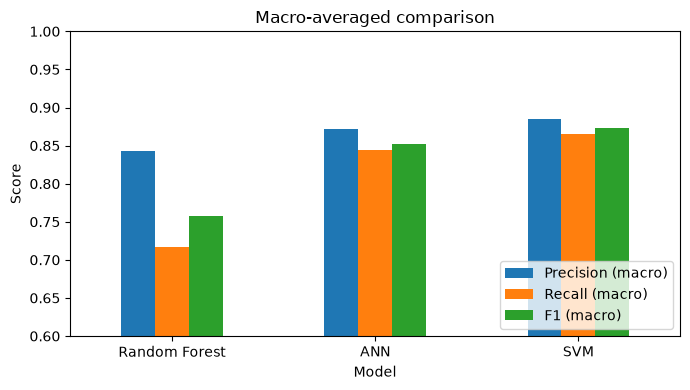

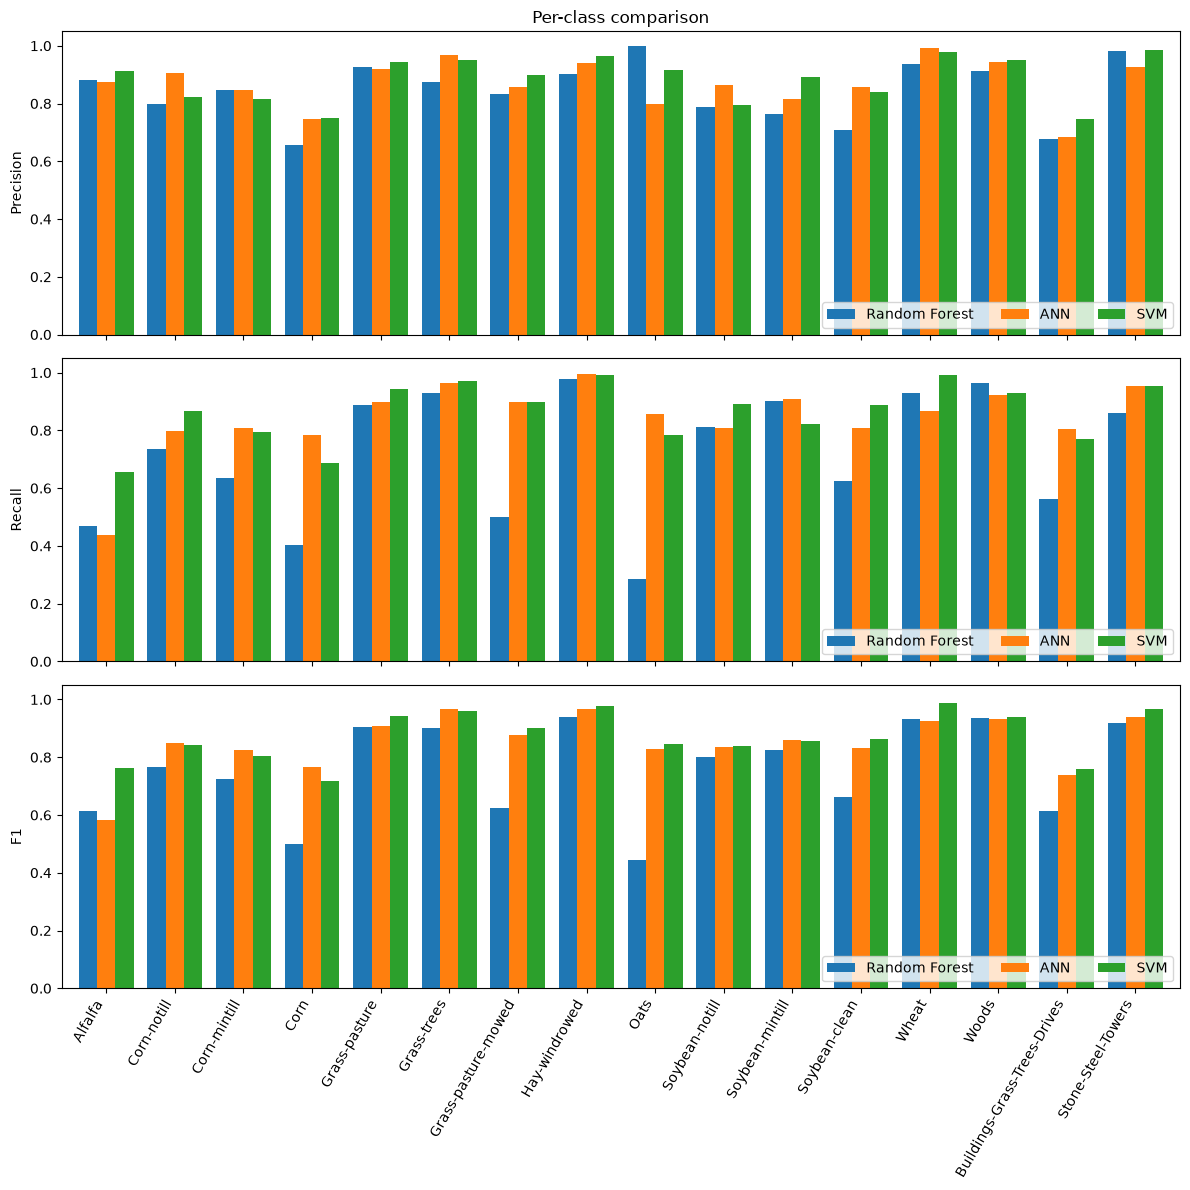

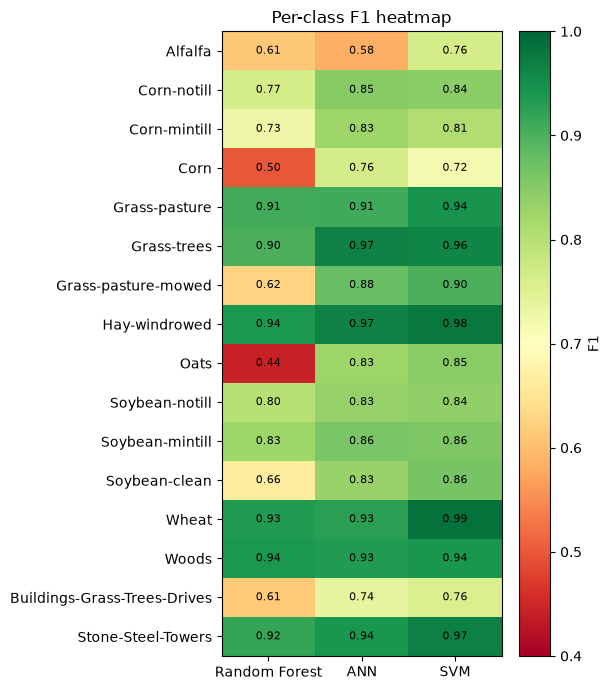

Best model per class (by F1):
Alfalfa                         SVM
Corn-notill                     ANN
Corn-mintill                    ANN
Corn                            ANN
Grass-pasture                   SVM
Grass-trees                     ANN
Grass-pasture-mowed             SVM
Hay-windrowed                   SVM
Oats                            SVM
Soybean-notill                  SVM
Soybean-mintill                 ANN
Soybean-clean                   SVM
Wheat                           SVM
Woods                           SVM
Buildings-Grass-Trees-Drives    SVM
Stone-Steel-Towers              SVM


In [6]:
from sklearn.metrics import precision_recall_fscore_support

preds = {"Random Forest": pred_rf, "ANN": pred_ann, "SVM": pred_svm}

# ---- 1) overall comparison (macro, weighted, accuracy, kappa) ----
rows = []
for name, p in preds.items():
    row = {"Model": name, "Accuracy": accuracy_score(y_test, p),
           "Kappa": cohen_kappa_score(y_test, p)}
    for avg in ["macro", "weighted"]:
        pr, rc, f1, _ = precision_recall_fscore_support(y_test, p, average=avg, zero_division=0)
        row.update({f"Precision ({avg})": pr, f"Recall ({avg})": rc, f"F1 ({avg})": f1})
    rows.append(row)
summary = pd.DataFrame(rows).set_index("Model").round(4)
print(summary.T, "\n")

# ---- 2) per-class precision / recall / F1 for each model ----
per_class = {}
for name, p in preds.items():
    pr, rc, f1, _ = precision_recall_fscore_support(y_test, p, labels=np.unique(y_test), zero_division=0)
    per_class[name] = pd.DataFrame({"Precision": pr, "Recall": rc, "F1": f1}, index=class_names)
per_class_df = pd.concat(per_class, axis=1).round(3)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
print(per_class_df, "\n")

# ---- 3) bar chart: overall macro scores ----
summary[["Precision (macro)", "Recall (macro)", "F1 (macro)"]].plot(
    kind="bar", figsize=(7, 4), rot=0)
plt.ylim(0.6, 1); plt.ylabel("Score"); plt.title("Macro-averaged comparison")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

# ---- 4) bar charts: per-class precision, recall, F1 ----
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)
for ax, metric in zip(axes, ["Precision", "Recall", "F1"]):
    pd.DataFrame({n: per_class[n][metric] for n in preds}).plot(kind="bar", ax=ax, width=0.8)
    ax.set_ylabel(metric); ax.set_ylim(0, 1.05); ax.legend(loc="lower right", ncol=3)
axes[0].set_title("Per-class comparison")
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()

# ---- 5) heatmap of per-class F1 ----
f1_table = pd.DataFrame({n: per_class[n]["F1"] for n in preds})
plt.figure(figsize=(6, 7)); plt.imshow(f1_table.values, cmap="RdYlGn", vmin=0.4, vmax=1, aspect="auto")
plt.xticks(range(3), f1_table.columns); plt.yticks(range(len(class_names)), class_names)
for i in range(f1_table.shape[0]):
    for j in range(3): plt.text(j, i, f"{f1_table.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(label="F1"); plt.title("Per-class F1 heatmap"); plt.tight_layout(); plt.show()

print("Best model per class (by F1):")
print(f1_table.idxmax(axis=1).to_string())